# Retail Sales and Profit Analysis

## Project Overview
This project analyzes retail sales data to identify sales trends,
profitability, customer behavior and regional performance.

## Objectives
- Clean and preprocess retail sales data.
- Analyze sales and profit performance.
- Identify top-performing products and categories.
- Discover business trends through data visualization.
- Provide actionable business recommendations.

## Executive Summary

This project analyzes 9,994 retail transaction records from
2014 to 2017 to evaluate sales, profitability, customer
behavior and regional performance.

### Key Results

- Total Revenue: $2,297,200.86
- Total Profit: $286,397.02
- Total Orders: 5,009
- Total Customers: 793
- Overall Profit Margin: 12.47%
- Average Order Value: $458.61
- Total Units Sold: 37,873

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [4]:
df=pd.read_csv("superstore.csv",encoding="latin1")
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


## Data Quality Assessment

In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate Rows:
0

Data Types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [50]:
print("Unique Values:")
print(df.nunique())

Unique Values:
Row ID           9994
Order ID         5009
Order Date       1237
Ship Date        1334
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              531
State              49
Postal Code       631
Region              4
Product ID       1862
Category            3
Sub-Category       17
Product Name     1850
Sales            5825
Quantity           14
Discount           12
Profit           7287
Year                4
Month              12
Month Name         12
Shipping Days       8
Profit Margin     525
dtype: int64


## Data Cleaning

In [9]:
df.columns=df.columns.str.strip()

print("Column Names:")
print(df.columns)

Column Names:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')


In [10]:
print("Duplicates Before Cleaning:")
print(df.duplicated().sum())

df=df.drop_duplicates()

print("\nDuplicates After Cleaning:")
print(df.duplicated().sum())

Duplicates Before Cleaning:
0

Duplicates After Cleaning:
0


In [11]:
print("Columns with Missing Values:")
print(df.isnull().sum()[df.isnull().sum()>0])

Columns with Missing Values:
Series([], dtype: int64)


In [12]:
print(df[["Order Date","Ship Date"]].head(10))

   Order Date   Ship Date
0   11/8/2016  11/11/2016
1   11/8/2016  11/11/2016
2   6/12/2016   6/16/2016
3  10/11/2015  10/18/2015
4  10/11/2015  10/18/2015
5    6/9/2014   6/14/2014
6    6/9/2014   6/14/2014
7    6/9/2014   6/14/2014
8    6/9/2014   6/14/2014
9    6/9/2014   6/14/2014


In [13]:
print("Updated Shape:")
print(df.shape)

df.info()

Updated Shape:
(9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-nu

## Data Preprocessing

In [54]:
df["Order Date"]=pd.to_datetime(df["Order Date"],format="%m/%d/%Y")
df["Ship Date"]=pd.to_datetime(df["Ship Date"],format="%m/%d/%Y")

print("Updated Data Types:")
print(df.dtypes)

Updated Data Types:
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
Year                      int32
Month                     int32
Month Name               object
Shipping Days             int64
Profit Margin           float64
dtype: object


In [16]:
df["Year"]=df["Order Date"].dt.year
df["Month"]=df["Order Date"].dt.month
df["Month Name"]=df["Order Date"].dt.month_name()

df[["Order Date","Year","Month","Month Name"]].head()

,Order Date,Year,Month,Month Name
0,2016-11-08,2016,11,November
1,2016-11-08,2016,11,November
2,2016-06-12,2016,6,June
3,2015-10-11,2015,10,October
4,2015-10-11,2015,10,October


In [17]:
df["Shipping Days"]=(df["Ship Date"]-df["Order Date"]).dt.days

df[["Order Date","Ship Date","Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2016-11-08,2016-11-11,3
1,2016-11-08,2016-11-11,3
2,2016-06-12,2016-06-16,4
3,2015-10-11,2015-10-18,7
4,2015-10-11,2015-10-18,7


In [18]:
df["Profit Margin"]=df["Profit"].div(df["Sales"].replace(0,np.nan))*100

df[["Sales","Profit","Profit Margin"]].head()

,Sales,Profit,Profit Margin
0,261.9600,41.9136,16.00
1,731.9400,219.5820,30.00
2,14.6200,6.8714,47.00
3,957.5775,-383.0310,-40.00
4,22.3680,2.5164,11.25


In [19]:
print("Final Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nNegative Shipping Days:")
print((df["Shipping Days"]<0).sum())

df.head()

Final Dataset Shape:
(9994, 26)

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Year             0
Month            0
Month Name       0
Shipping Days    0
Profit Margin    0
dtype: int64

Duplicate Rows:
0

Negative Shipping Days:
0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Shipping Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,7,11.25


## Exploratory Data Analysis

### Key Performance Indicators (KPIs)

In [21]:
total_sales=df["Sales"].sum()
total_profit=df["Profit"].sum()
total_orders=df["Order ID"].nunique()
total_customers=df["Customer ID"].nunique()
total_quantity=df["Quantity"].sum()
profit_margin=(total_profit/total_sales)*100

print("Total Sales: $",round(total_sales,2))
print("Total Profit: $",round(total_profit,2))
print("Total Orders:",total_orders)
print("Total Customers:",total_customers)
print("Total Quantity Sold:",total_quantity)
print("Profit Margin:",round(profit_margin,2),"%")

Total Sales: $ 2297200.86
Total Profit: $ 286397.02
Total Orders: 5009
Total Customers: 793
Total Quantity Sold: 37873
Profit Margin: 12.47 %


### Category-wise Sales and Profit Analysis

In [23]:
category=df.groupby("Category")[["Sales","Profit","Quantity"]].sum()
category

,Sales,Profit,Quantity
Category,,,
Furniture,741999.7953,18451.2728,8028
Office Supplies,719047.0320,122490.8008,22906
Technology,836154.0330,145454.9481,6939


In [24]:
sub_category=df.groupby("Sub-Category")[["Sales","Profit"]].sum()
sub_category.sort_values("Sales",ascending=False)

,Sales,Profit
Sub-Category,,
Phones,330007.0540,44515.7306
Chairs,328449.1030,26590.1663
Storage,223843.6080,21278.8264
Tables,206965.5320,-17725.4811
Binders,203412.7330,30221.7633
Machines,189238.6310,3384.7569
Accessories,167380.3180,41936.6357
Copiers,149528.0300,55617.8249
Bookcases,114879.9963,-3472.5560


### Regional Performance Analysis

In [26]:
region=df.groupby("Region")[["Sales","Profit"]].sum()
region.sort_values("Sales",ascending=False)

,Sales,Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
Central,501239.8908,39706.3625
South,391721.9050,46749.4303


In [27]:
state=df.groupby("State")[["Sales","Profit"]].sum()
state.sort_values("Sales",ascending=False).head(10)

,Sales,Profit
State,,
California,457687.6315,76381.3871
New York,310876.2710,74038.5486
Texas,170188.0458,-25729.3563
Washington,138641.2700,33402.6517
Pennsylvania,116511.9140,-15559.9603
Florida,89473.7080,-3399.3017
Illinois,80166.1010,-12607.8870
Ohio,78258.1360,-16971.3766
Michigan,76269.6140,24463.1876


### Yearly and Monthly Sales Analysis

In [29]:
yearly=df.groupby("Year")[["Sales","Profit"]].sum()
yearly

,Sales,Profit
Year,,
2014,484247.4981,49543.9741
2015,470532.5090,61618.6037
2016,609205.5980,81795.1743
2017,733215.2552,93439.2696


In [30]:
monthly=df.groupby(["Year","Month"])[["Sales","Profit"]].sum()
monthly

Sales      Profit
Year Month                         
2014 1       14236.8950   2450.1907
     2        4519.8920    862.3084
     3       55691.0090    498.7299
     4       28295.3450   3488.8352
     5       23648.2870   2738.7096
     6       34595.1276   4976.5244
     7       33946.3930   -841.4826
     8       27909.4685   5318.1050
     9       81777.3508   8328.0994
     10      31453.3930   3448.2573
     11      78628.7167   9292.1269
     12      69545.6205   8983.5699
2015 1       18174.0756  -3281.0070
     2       11951.4110   2813.8508
     3       38726.2520   9732.0978
     4       34195.2085   4187.4962
     5       30131.6865   4667.8690
     6       24797.2920   3335.5572
     7       28765.3250   3288.6483
     8       36898.3322   5355.8084
     9       64595.9180   8209.1627
     10      31404.9235   2817.3660
     11      75972.5635  12474.7884
     12      74919.5212   8016.9659
2016 1       18542.4910   2824.8233
     2       22978.8150   5004.5795
     3       51715.8750   3611.9680
     4       38750.0390   2977.8149
     5       56987.7280   8662.1464
     6       40344.5340   4750.3781
     7       39261.9630   4432.8779
     8       31115.3743   2062.0693
     9       73410.0249   9328.6576
     10      59687.7450  16243.1425
     11      79411.9658   4011.4075
     12      96999.0430  17885.3093
2017 1       43971.3740   7140.4391
     2       20301.1334   1613.8720
     3       58872.3528  14751.8915
     4       36521.5361    933.2900
     5       44261.1102   6342.5828
     6       52981.7257   8223.3357
     7       45264.4160   6952.6212
     8       63120.8880   9040.9557
     9       87866.6520  10991.5556
     10      77776.9232   9275.2755
     11     118447.8250   9690.1037
     12      83829.3188   8483.3468

In [31]:
segment=df.groupby("Segment")[["Sales","Profit"]].sum()
segment

,Sales,Profit
Segment,,
Consumer,1.161401e+06,134119.2092
Corporate,7.061464e+05,91979.1340
Home Office,4.296531e+05,60298.6785


In [32]:
print("Loss-Making Sub-Categories:")
print(sub_category[sub_category["Profit"]<0])

Loss-Making Sub-Categories:
                    Sales      Profit
Sub-Category                         
Bookcases     114879.9963  -3472.5560
Supplies       46673.5380  -1189.0995
Tables        206965.5320 -17725.4811


## Data Visualization


In [34]:
sns.set_theme(style="whitegrid",palette="deep")

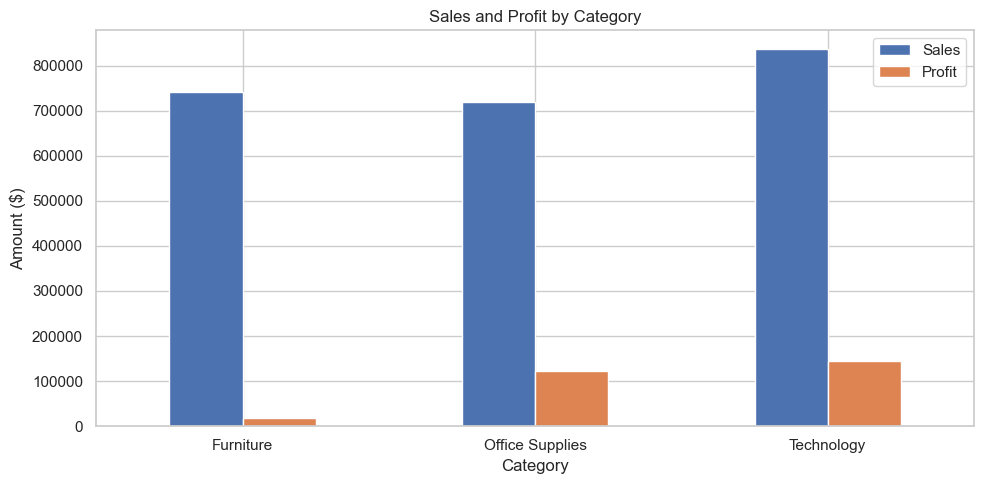

In [35]:
category[["Sales","Profit"]].plot(kind="bar",figsize=(10,5))
plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

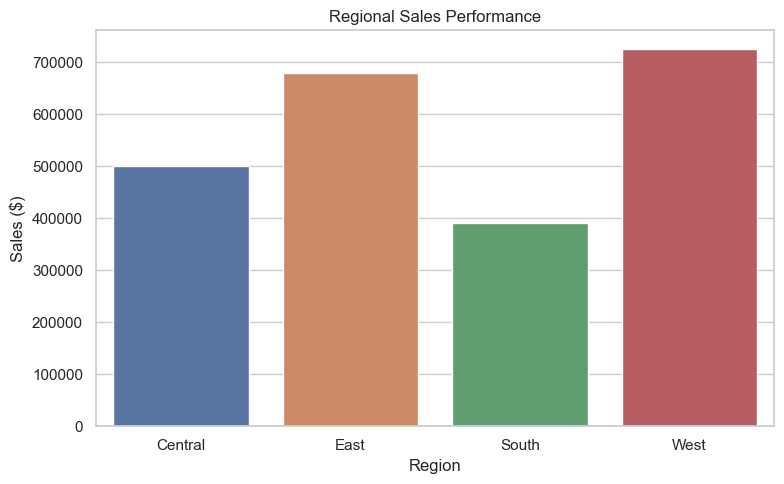

In [36]:
plt.figure(figsize=(8,5))
sns.barplot(x=region.index,y=region["Sales"],hue=region.index,legend=False)
plt.title("Regional Sales Performance")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

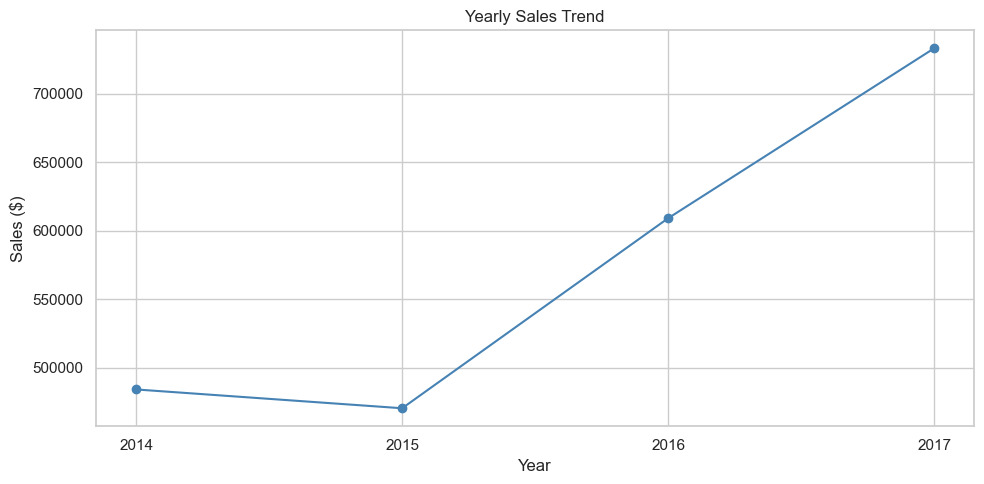

In [37]:
plt.figure(figsize=(10,5))
plt.plot(yearly.index,yearly["Sales"],marker="o",color="steelblue")
plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Sales ($)")
plt.xticks(yearly.index)
plt.tight_layout()
plt.show()

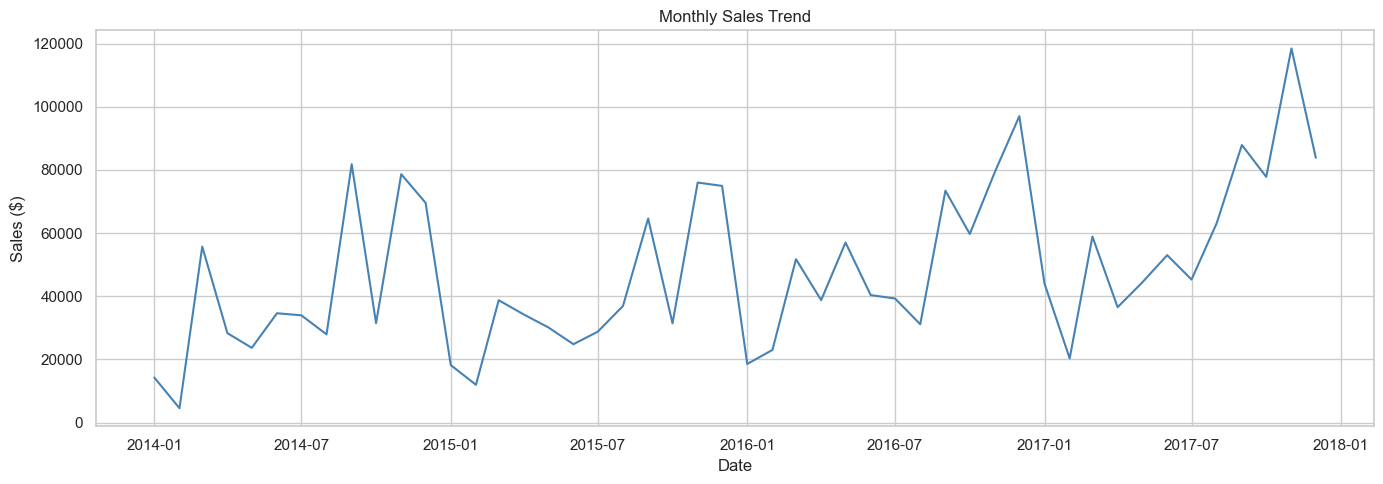

In [38]:
monthly_sales=df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()

plt.figure(figsize=(14,5))
plt.plot(monthly_sales.index.to_timestamp(),monthly_sales.values,color="steelblue")
plt.title("Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

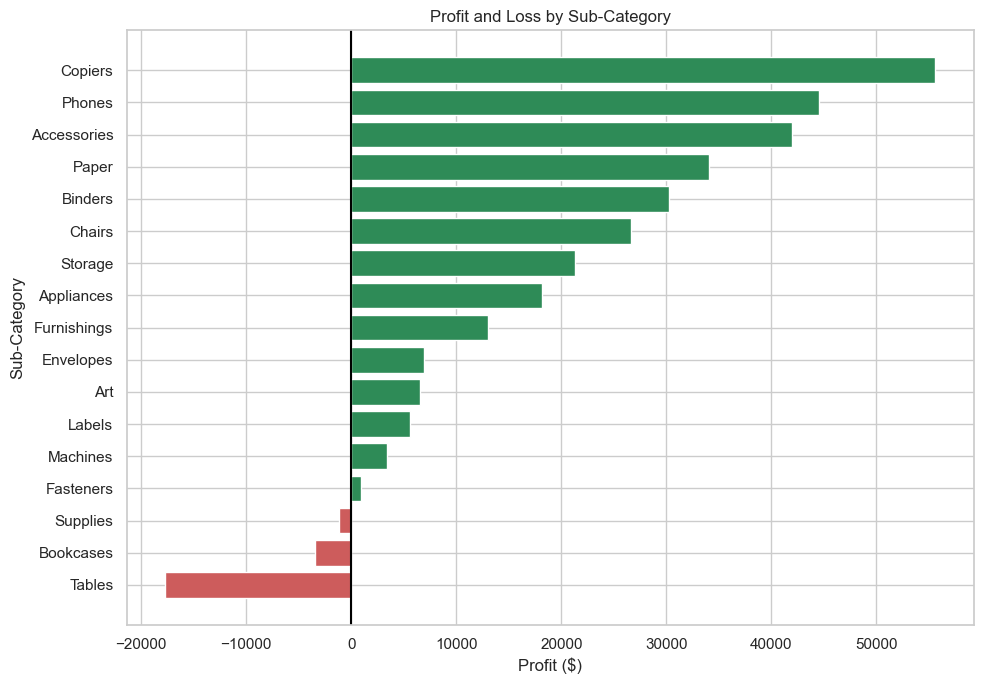

In [39]:
sub_profit=sub_category["Profit"].sort_values()

colors=["indianred" if p<0 else "seagreen" for p in sub_profit]

plt.figure(figsize=(10,7))
plt.barh(sub_profit.index,sub_profit.values,color=colors)
plt.axvline(0,color="black")
plt.title("Profit and Loss by Sub-Category")
plt.xlabel("Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

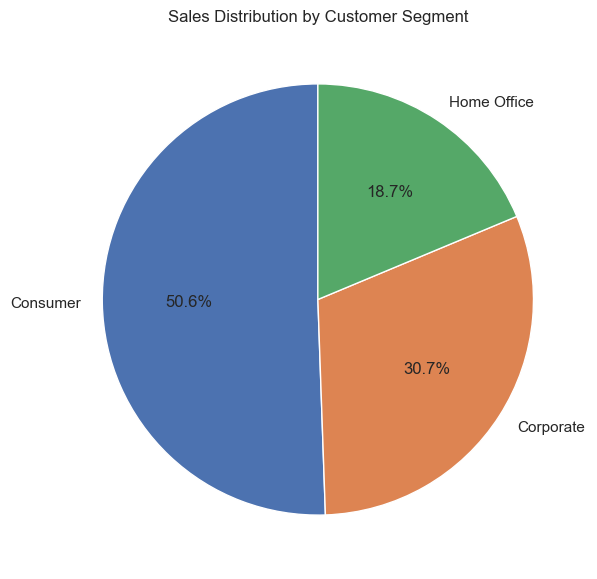

In [40]:
plt.figure(figsize=(7,7))
plt.pie(segment["Sales"],labels=segment.index,autopct="%1.1f%%",startangle=90)
plt.title("Sales Distribution by Customer Segment")
plt.show()

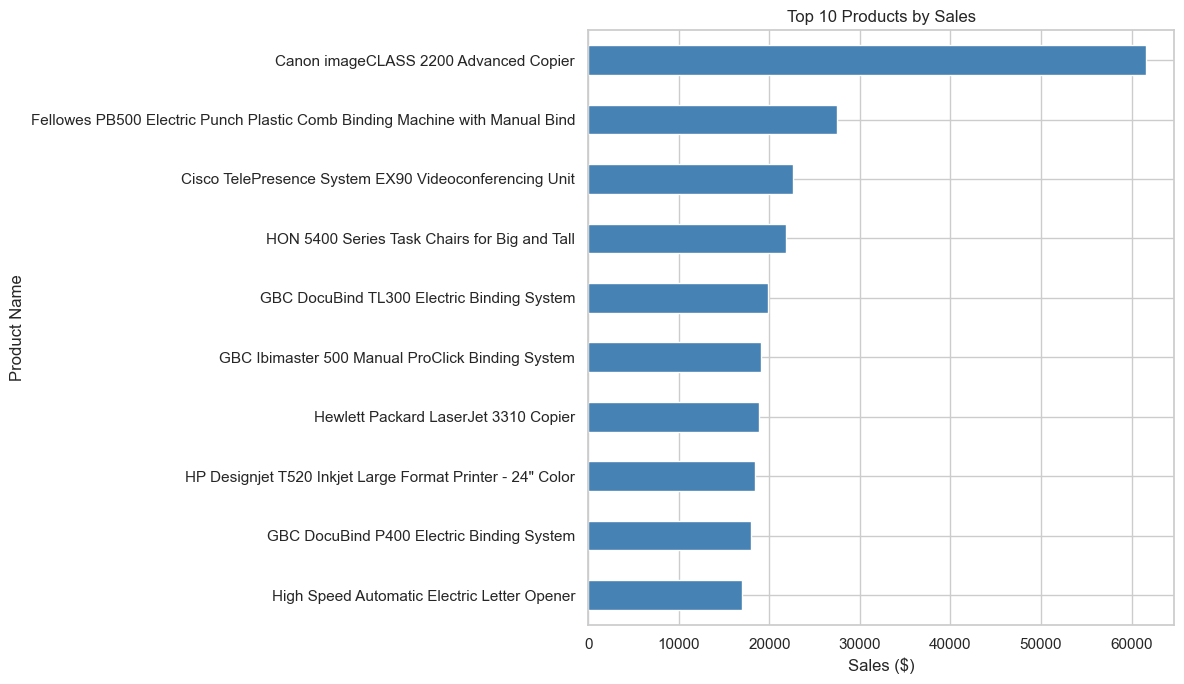

In [41]:
top_products=df.groupby("Product Name")["Sales"].sum()
top_products=top_products.sort_values(ascending=False).head(10)

plt.figure(figsize=(12,7))
top_products.sort_values().plot(kind="barh",color="steelblue")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales ($)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

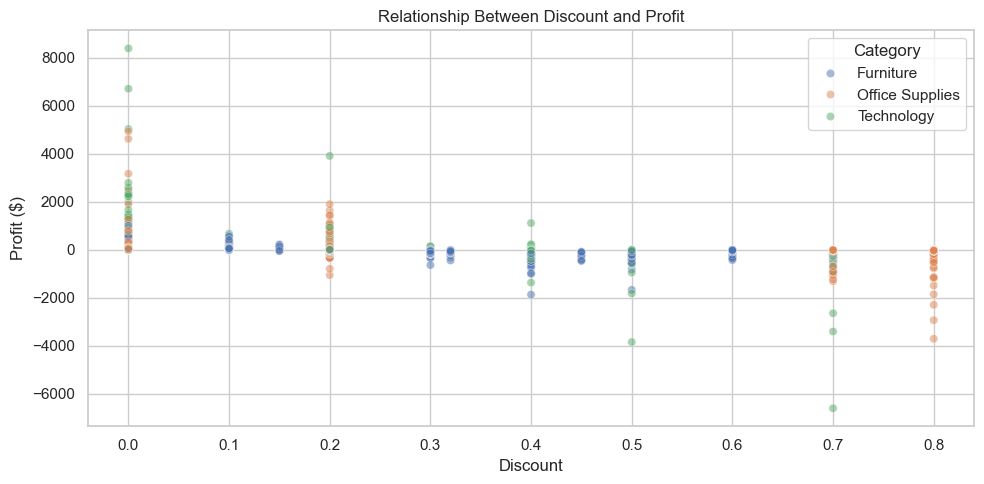

In [42]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df,x="Discount",y="Profit",hue="Category",alpha=0.5)
plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()

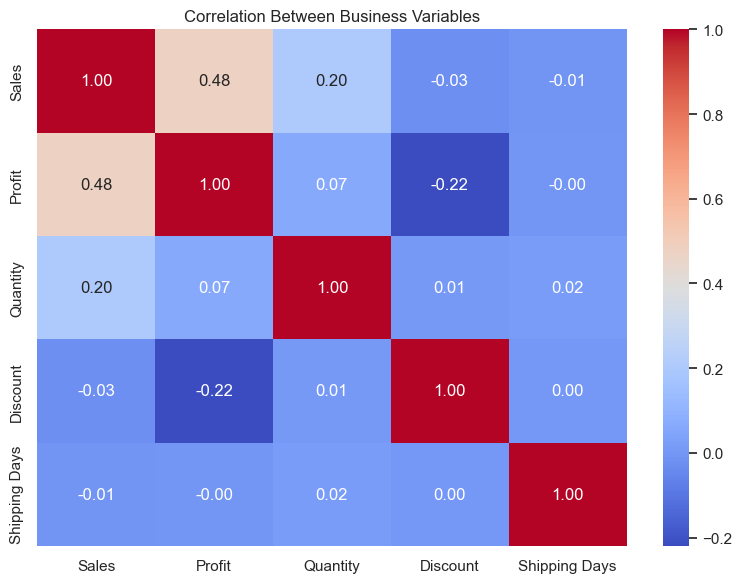

In [44]:
num_cols=["Sales","Profit","Quantity","Discount","Shipping Days"]

plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Between Business Variables")
plt.tight_layout()
plt.show()

## Retail Sales Performance Dashboard

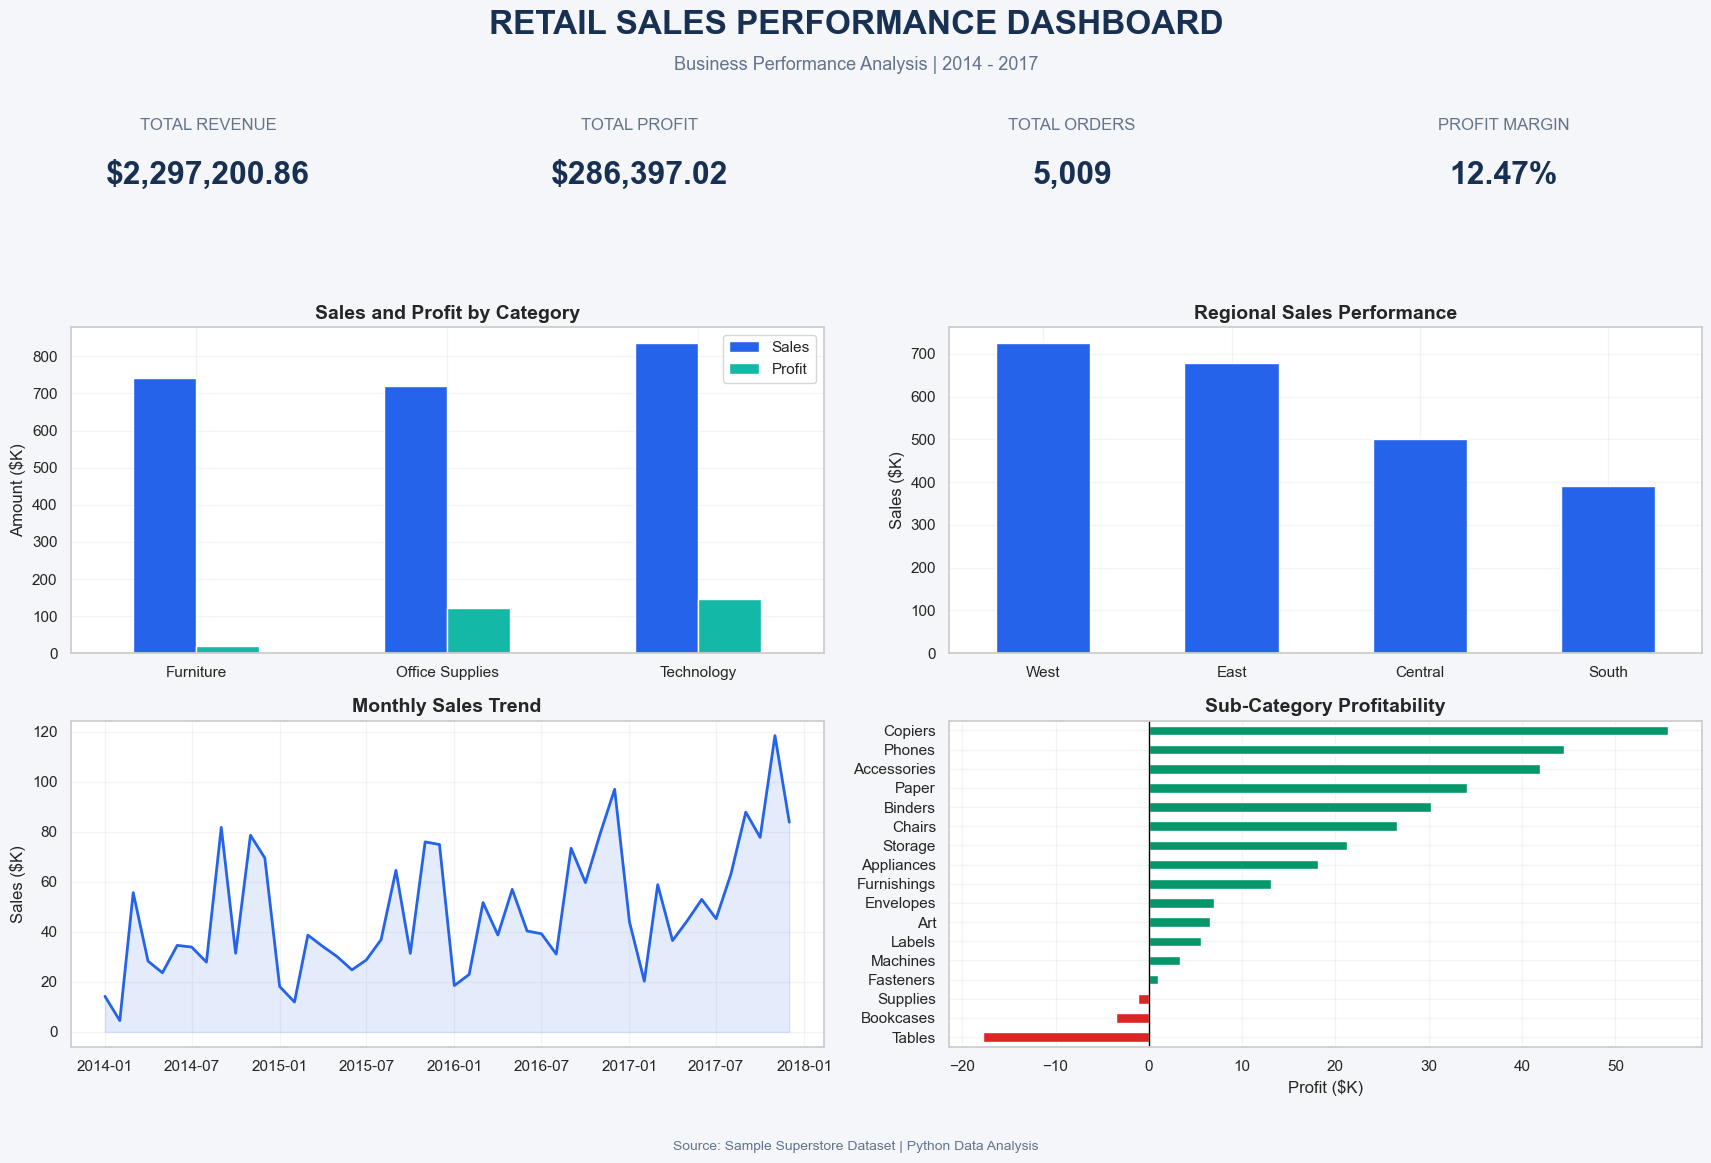

In [53]:
fig,ax=plt.subplots(2,2,figsize=(18,12))
fig.patch.set_facecolor("#F4F6F9")

fig.suptitle("RETAIL SALES PERFORMANCE DASHBOARD",
             fontsize=24,fontweight="bold",color="#183153",y=0.97)

fig.text(0.5,0.92,"Business Performance Analysis | 2014 - 2017",
         ha="center",fontsize=13,color="#64748B")

# KPI Cards
kpi_names=["TOTAL REVENUE","TOTAL PROFIT",
           "TOTAL ORDERS","PROFIT MARGIN"]

kpi_values=[f"${total_sales:,.2f}",
            f"${total_profit:,.2f}",
            f"{total_orders:,}",
            f"{profit_margin:.2f}%"]

positions=[0.14,0.38,0.62,0.86]

for i in range(4):
    fig.text(positions[i],0.87,kpi_names[i],
             ha="center",fontsize=12,color="#64748B")

    fig.text(positions[i],0.825,kpi_values[i],
             ha="center",fontsize=23,fontweight="bold",
             color="#183153")

# Category Performance
(category[["Sales","Profit"]]/1000).plot(
    kind="bar",ax=ax[0,0],color=["#2563EB","#14B8A6"])

ax[0,0].set_title("Sales and Profit by Category",
                  fontsize=14,fontweight="bold")
ax[0,0].set_ylabel("Amount ($K)")
ax[0,0].set_xlabel("")
ax[0,0].tick_params(axis="x",rotation=0)

# Regional Performance
(region["Sales"].sort_values(ascending=False)/1000).plot(
    kind="bar",ax=ax[0,1],color="#2563EB")

ax[0,1].set_title("Regional Sales Performance",
                  fontsize=14,fontweight="bold")
ax[0,1].set_ylabel("Sales ($K)")
ax[0,1].set_xlabel("")
ax[0,1].tick_params(axis="x",rotation=0)

# Monthly Sales Trend
ax[1,0].plot(monthly_sales.index.to_timestamp(),
             monthly_sales.values/1000,
             color="#2563EB",linewidth=2)

ax[1,0].fill_between(monthly_sales.index.to_timestamp(),
                     monthly_sales.values/1000,
                     color="#2563EB",alpha=0.12)

ax[1,0].set_title("Monthly Sales Trend",
                  fontsize=14,fontweight="bold")
ax[1,0].set_ylabel("Sales ($K)")

# Sub-Category Profitability
colors=[]

for p in sub_profit:
    if p<0:
        colors.append("#DC2626")
    else:
        colors.append("#059669")

(sub_profit/1000).plot(kind="barh",ax=ax[1,1],color=colors)

ax[1,1].set_title("Sub-Category Profitability",
                  fontsize=14,fontweight="bold")
ax[1,1].set_xlabel("Profit ($K)")
ax[1,1].set_ylabel("")
ax[1,1].axvline(0,color="black",linewidth=1)

# Chart Formatting
for a in ax.flat:
    a.set_facecolor("white")
    a.grid(alpha=0.2)
    a.set_axisbelow(True)

fig.text(0.5,0.02,"Source: Sample Superstore Dataset | Python Data Analysis",
         ha="center",fontsize=10,color="#64748B")

plt.tight_layout(rect=[0.02,0.05,0.98,0.78])

plt.savefig("Retail_Sales_Dashboard.png",
            dpi=300,bbox_inches="tight")

plt.show()

## Key Business Insights

In [48]:
print("Best-Selling Category:")
print(category["Sales"].idxmax())

print("\nMost Profitable Category:")
print(category["Profit"].idxmax())

print("\nBest-Performing Region by Sales:")
print(region["Sales"].idxmax())

print("\nMost Profitable Region:")
print(region["Profit"].idxmax())

print("\nHighest Sales Year:")
print(yearly["Sales"].idxmax())

print("\nLeast Profitable Sub-Category:")
print(sub_category["Profit"].idxmin())

print("\nHighest Revenue Customer Segment:")
print(segment["Sales"].idxmax())

print("\nAverage Order Value:")
print("$",round(total_sales/total_orders,2))

print("\nAverage Shipping Duration:")
print(round(df["Shipping Days"].mean(),2),"Days")

print("\nDiscount and Profit Correlation:")
print(round(df["Discount"].corr(df["Profit"]),2))

Best-Selling Category:
Technology

Most Profitable Category:
Technology

Best-Performing Region by Sales:
West

Most Profitable Region:
West

Highest Sales Year:
2017

Least Profitable Sub-Category:
Tables

Highest Revenue Customer Segment:
Consumer

Average Order Value:
$ 458.61

Average Shipping Duration:
3.96 Days

Discount and Profit Correlation:
-0.22


In [49]:
df.to_csv("Cleaned_Superstore.csv",index=False)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.


## Business Recommendations

### 1. Prioritize Technology Products

Technology generated the highest revenue of $836,154.03
and the highest profit of $145,454.95.

The business should prioritize inventory availability and
evaluate additional marketing opportunities in this category.

### 2. Improve Furniture Profitability

Despite generating $741,999.80 in sales, Furniture achieved
a profit margin of only 2.49%.

The business should review pricing, discounts and costs.

### 3. Address Loss-Making Products

Tables, Bookcases and Supplies generated combined losses
of $22,387.14.

The business should investigate product pricing, supplier
costs and discount policies for these sub-categories.

### 4. Improve Regional Performance

The West region generated the highest revenue and profit,
while the South generated the lowest revenue.

Successful strategies from the West should be evaluated
for potential application in other regions.

### 5. Optimize Discount Strategies

Discount and profit showed a negative correlation of -0.22.

The business should evaluate discount effectiveness and
avoid promotions that reduce profitability unnecessarily.
Correlation alone does not establish causation.

### 6. Focus on Consumer Customers

The Consumer segment contributed approximately 50.56%
of total revenue.

Customer retention and targeted marketing strategies
should be evaluated for this segment.

## Conclusion

This project demonstrates how Python-based data analysis
can transform retail transaction data into meaningful
business insights.

The analysis identifies sales trends, profitable categories,
regional performance differences and loss-making products.

These findings can support informed decisions related to
pricing, inventory, marketing and profitability.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook